# Introduction

This notebook presents a comprehensive set of neural network architectures and models for lung scan classification.

**SimpleConvNet** (Simple Convolutional Network):
A lightweight convolutional neural network with multiple convolution and pooling layers, followed by fully connected layers. Designed for efficient classification on 256x256 lung scan images.

**Modified AlexNet**:
An enhanced version of the classic AlexNet architecture with optimized fully connected layers for lung scan classification on 224x224 images.

**HybridNet** (Hybrid Autoencoder + AlexNet):
Combines an autoencoder with modified AlexNet architecture. Note: This model was removed due to gradient explosion issues during training.

**LungsWithMasksDataset**:
Custom dataset combining lung scan images with their corresponding segmentation masks. Enables training of models with mask-enhanced features to focus on lung tissue.

**SimpleConvNet with Masks**:
SimpleConvNet adapted to utilize lung segmentation masks during training. Masks guide the model to focus on lung tissue regions, potentially improving classification accuracy.

**Modified AlexNet with Masks**:
AlexNet enhanced with mask-guided feature extraction. Combines the power of deeper architecture with focused feature learning on lung regions.

HybridNet с масками:
 К сожалению модель пришлось удалить из-за взрывающихся градиентов. Модель состояла из автоэнкодера и модифицированного alexnet.

**UNet for Lung Segmentation**:
A specialized UNet architecture trained to automatically generate lung segmentation masks from raw CT scan images. These masks are used to enhance training of classification models.

**Mask Generation and Storage**:
Automatic generation of lung masks for all training and test images using the trained UNet model. Masks are saved for use in mask-enhanced classification models.

**Training and Evaluation**:
Complete training loops for all models with comprehensive evaluation metrics (Loss, F1-Score, Recall, Precision) and visualization of training progress.


# 0.0 Device and Magic Code

In [30]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

Defining Device

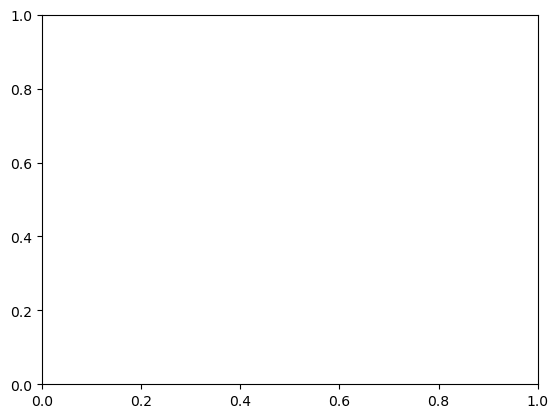

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

plt.show()

Magic code - do not touch

# Creating a DataLoader for Lung Scans

In [32]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import *
from torchvision import datasets, transforms
import os
from PIL import Image
import pandas as pd


class LungsDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        image_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(image_path).convert('RGB')
        
        label = self.df.iloc[idx, 1]

        if self.transform:
            image = self.transform(image)

        return image, label


raw_transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_train_raw = LungsDataset(csv_file='data/train_answers.csv', root_dir='data/train_images', transform=raw_transform)

In [33]:
data_train_raw[0][0].shape

torch.Size([1, 256, 256])

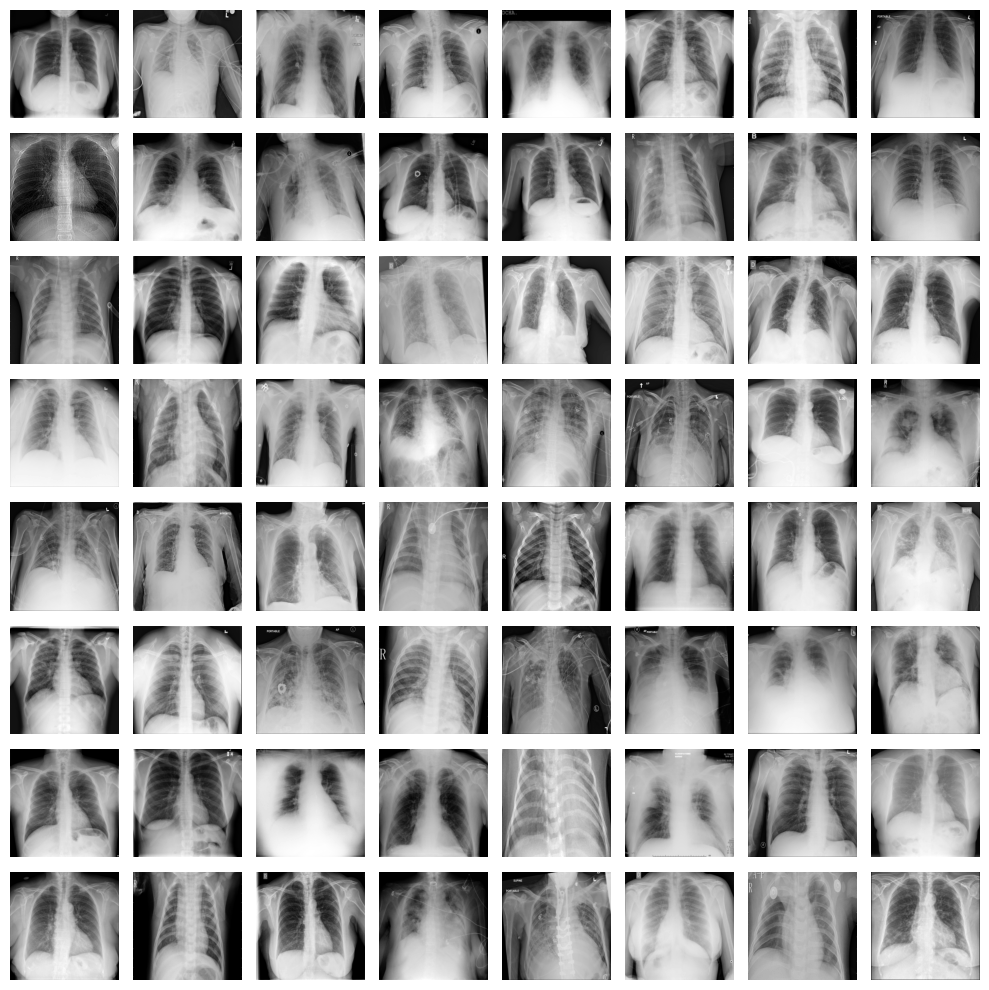

In [34]:
import torchshow as ts

x = torch.stack([data_train_raw[i][0] for i in range(64)]).to(device)
ts.show(x, nrows=8, figsize=(10, 10))

# Defining Training Functions

In [35]:
from tqdm import tqdm
from sklearn.metrics import f1_score, recall_score, precision_score
import torch.nn.functional as F

def run_epoch(mdl, opt, loss, dataloader, is_train=True):
    mdl.train(is_train)
    total_loss = 0.0
    
    all_labels = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for x, y in tqdm(dataloader):
            x = x.to(device)
            y = y.to(device)
            
            y_pred = mdl(x)
            
            l = loss(y_pred, y)
            if (is_train):
                opt.zero_grad()
                l.backward()
                
                opt.step()
            
            
            total_loss += l.item() # loss
            
            correct_idx = y.detach().cpu().numpy()
            all_labels.extend(correct_idx)

            predicted_idx = torch.argmax(F.softmax(y_pred.detach(), dim=1), dim=1).cpu().numpy()
            all_predictions.extend(predicted_idx)
    
    return {"Loss": total_loss / len(dataloader.dataset), "F1": f1_score(all_labels, all_predictions, average='macro'), "Recall": recall_score(all_labels, all_predictions, average='macro'), "Precision": precision_score(all_labels, all_predictions, average='macro')}

In [36]:
import numpy as np

def subplot_metrics(metrics, title, num_epochs):
    plt.title(title)
    
    x = np.arange(len(metrics["Train"]))
    
    for lbl, hst in metrics.items():
        plt.plot(x, hst, label=lbl)
    
    plt.grid()
    plt.xticks(np.arange(num_epochs))
    plt.legend()

def plot_metrics(metrics_hist, num_epochs):
    plt.figure(figsize=(16, 8.5))
    
    plt.subplot(2, 2, 1)
    subplot_metrics(metrics_hist["Loss"], f'Loss = {metrics_hist["Loss"]["Train"][-1]}, {metrics_hist["Loss"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 2)
    subplot_metrics(metrics_hist["F1"], f'F1 = {metrics_hist["F1"]["Train"][-1]}, {metrics_hist["F1"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 3)
    subplot_metrics(metrics_hist["Recall"], f'Recall = {metrics_hist["Recall"]["Train"][-1]}, {metrics_hist["Recall"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 4)
    subplot_metrics(metrics_hist["Precision"], f'Precision = {metrics_hist["Precision"]["Train"][-1]}, {metrics_hist["Precision"]["Test"][-1]}', num_epochs)
    
    plt.subplots_adjust(wspace=0.5)
    plt.show()

In [37]:
from IPython.display import clear_output

def run_train_loop(mdl, opt, loss, train_loader, val_loader, num_epochs):
    train_hist = []
    val_hist = []
    metrics_hist = {"Loss": {"Train": [], "Test": []}, "F1":  {"Train": [], "Test": []}, "Recall":  {"Train": [], "Test": []}, "Precision":  {"Train": [], "Test": []}}
    
    for e in range(num_epochs):
        print("Trainin...")
        train_metrics = run_epoch(mdl, opt, loss, train_loader)
        for key in metrics_hist.keys():
            metrics_hist[key]["Train"].append(train_metrics[key])
        
        print("Validating...")
        val_metrics = run_epoch(mdl, opt, loss, val_loader, is_train=False)
        for key in metrics_hist.keys():
            metrics_hist[key]["Test"].append(val_metrics[key])
        
        clear_output()
        plot_metrics(metrics_hist, num_epochs)

# Classification Models Without Masks

In [38]:
import torch.nn as nn
from torchsummary import summary
from torch.utils.data.dataset import random_split
from torch.utils.data import DataLoader

# SimpleConvNet: Simple Convolutional Solution

In [39]:
class SimpleConvNet(nn.Module):
    def __init__(self):
        super(SimpleConvNet, self).__init__()

        self.conv = nn.Sequential( # in 1 256 256
            nn.Conv2d(1, 16, 5), # out 16 252 252
            nn.ReLU(),
            nn.Conv2d(16, 16, 5), # out 16 248 248
            nn.ReLU(),
            nn.MaxPool2d(4, 4), # out 4 62 62
            nn.Conv2d(16, 32, 5), # out 32 58 58
            nn.ReLU(),
            nn.Conv2d(32, 32, 5), # out 32 54 54
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # out 16 27 27
            nn.Conv2d(32, 64, 4), # out 64 24 24
            nn.ReLU(),
            nn.Conv2d(64, 64, 5), # out 64 20 20
            nn.ReLU(),
            nn.MaxPool2d(4, 4), # out 64 5 5
            nn.Conv2d(64, 128, 5), # out 128 1 1
            nn.Flatten() # out 128
        )
        
        self.linear = nn.Sequential(
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 3) # no activation
        )
    
    def forward(self, x):
        x = self.conv(x)
        x = self.linear(x)
        return x


simple_conv_model = SimpleConvNet().to(device)
summary(simple_conv_model, (1, 256, 256), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 252, 252]             416
              ReLU-2         [-1, 16, 252, 252]               0
            Conv2d-3         [-1, 16, 248, 248]           6,416
              ReLU-4         [-1, 16, 248, 248]               0
         MaxPool2d-5           [-1, 16, 62, 62]               0
            Conv2d-6           [-1, 32, 58, 58]          12,832
              ReLU-7           [-1, 32, 58, 58]               0
            Conv2d-8           [-1, 32, 54, 54]          25,632
              ReLU-9           [-1, 32, 54, 54]               0
        MaxPool2d-10           [-1, 32, 27, 27]               0
           Conv2d-11           [-1, 64, 24, 24]          32,832
             ReLU-12           [-1, 64, 24, 24]               0
           Conv2d-13           [-1, 64, 20, 20]         102,464
             ReLU-14           [-1, 64,

In [40]:
num_samples = len(data_train_raw)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train_raw, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


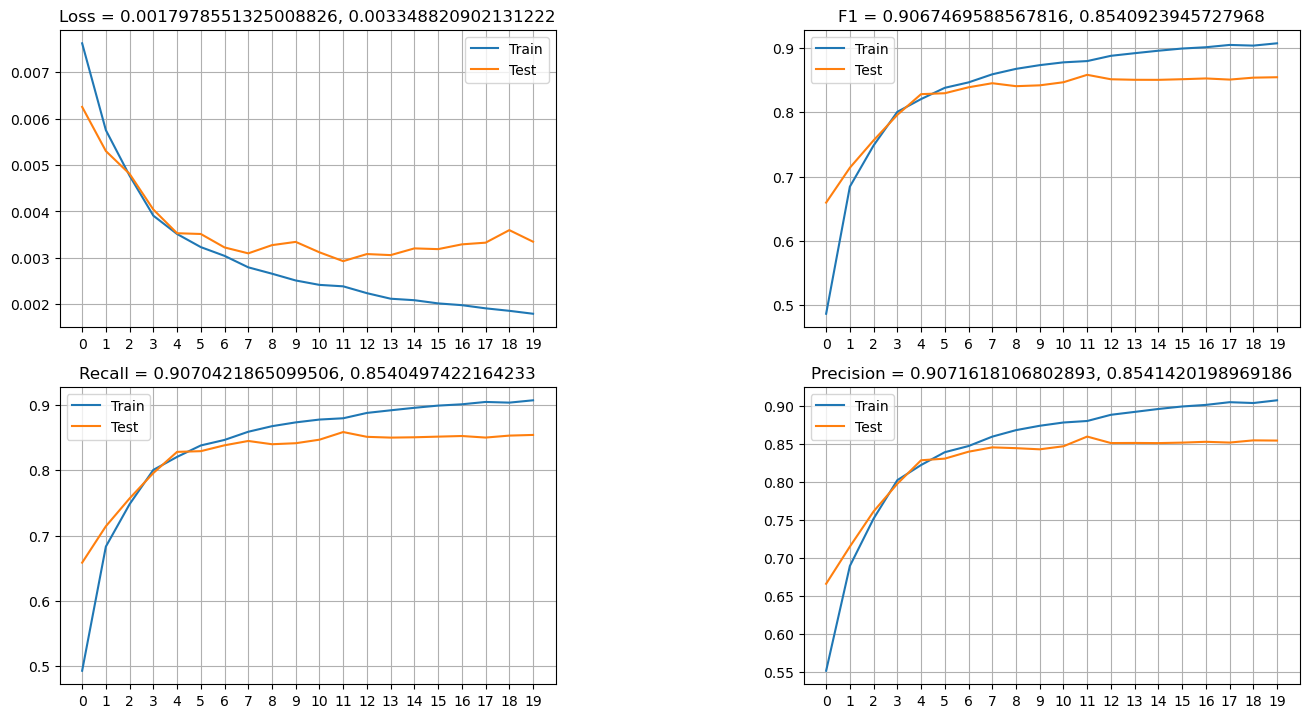

In [41]:
batch_size = 128
num_epochs = 20 # 15

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(simple_conv_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(simple_conv_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

# Modified AlexNet Architecture

In [42]:
class AlexNet(nn.Module):
    def __init__(self, num_classes: int = 3, dropout: float = 0.5) -> None:
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(256 * 6 * 6, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(1024, 1024),
            nn.ReLU(inplace=True),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Dropout(p=dropout),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


alex_net_model = AlexNet().to(device)
summary(alex_net_model, (1, 224, 224), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 55, 55]           7,808
              ReLU-2           [-1, 64, 55, 55]               0
         MaxPool2d-3           [-1, 64, 27, 27]               0
            Conv2d-4          [-1, 192, 27, 27]         307,392
              ReLU-5          [-1, 192, 27, 27]               0
         MaxPool2d-6          [-1, 192, 13, 13]               0
            Conv2d-7          [-1, 384, 13, 13]         663,936
              ReLU-8          [-1, 384, 13, 13]               0
            Conv2d-9          [-1, 256, 13, 13]         884,992
             ReLU-10          [-1, 256, 13, 13]               0
           Conv2d-11          [-1, 256, 13, 13]         590,080
             ReLU-12          [-1, 256, 13, 13]               0
        MaxPool2d-13            [-1, 256, 6, 6]               0
AdaptiveAvgPool2d-14            [-1, 25

In [43]:
alex_transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((224, 224), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(mean=0.5, std=0.5)
])

data_train_alexnet = LungsDataset(csv_file='data/train_answers.csv', root_dir='data/train_images', transform=alex_transform)

num_samples = len(data_train_alexnet)
num_test = int(0.1 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train_alexnet, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 24300 
 Test len: 2700


In [44]:
data_train_alexnet[0][0].shape

torch.Size([1, 224, 224])

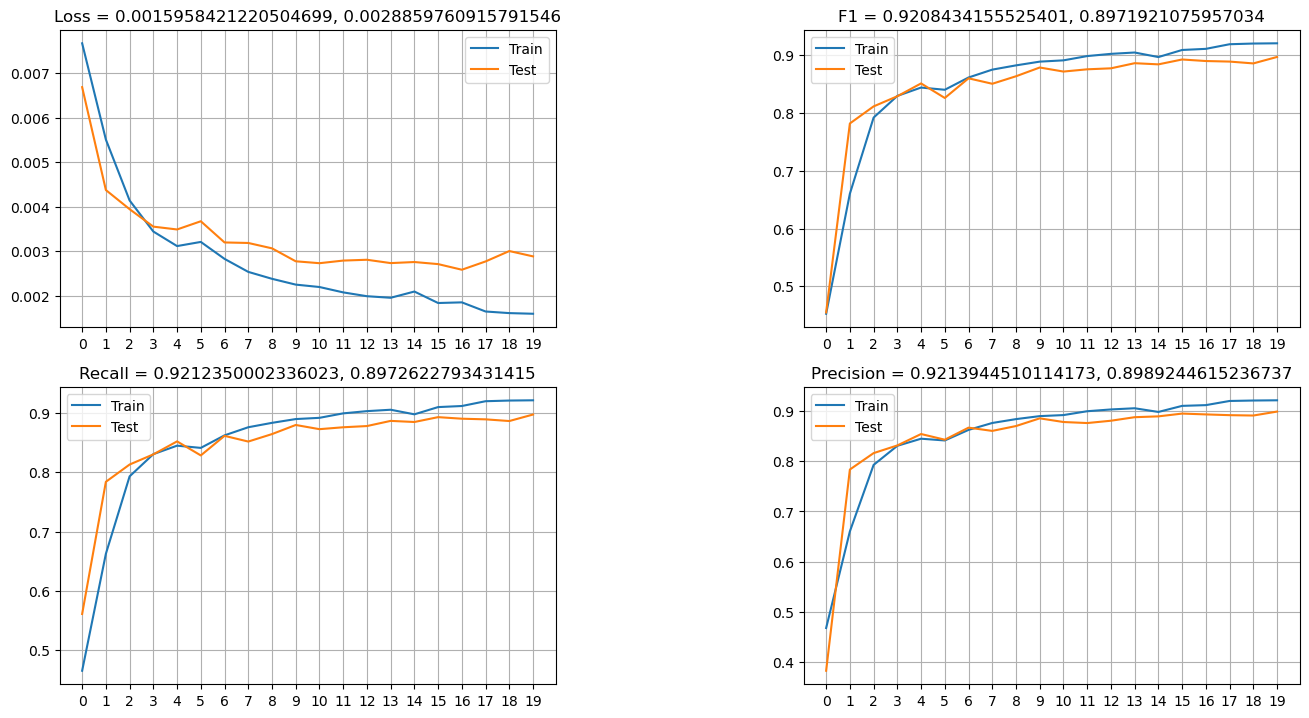

In [45]:
batch_size = 128
num_epochs = 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

In [46]:
# Saving Data
data_main_test = LungsDataset(csv_file='data/train_answers.csv', root_dir='data/test_images', transform=alex_transform)

data = []
alex_net_model.eval()
with torch.no_grad():
    for i in range(len(data_main_test)):
        inp = data_main_test[i][0].clone().detach()
        inp = inp.unsqueeze(0)
        inp = inp.to(device)
        
        output = alex_net_model(inp)
        
        predicted_id =  torch.argmax(F.softmax(output, dim=1)).item()
        data.append([i, predicted_id])

df = pd.DataFrame(data)

file_path = 'alex_answers.csv'

df.columns = ['id', 'target_feature']
df.to_csv(file_path, index=False, header=True)

print(f'CSV file saved to: {file_path}')

CSV file saved to: alex_answers.csv


# Lung Mask Detection and Segmentation

# Mask Dataset Creation

In [54]:
class MaskDataset(Dataset):
    def __init__(self, y_dir, x_dir, transform=None):
        self.x_dir = x_dir
        self.y_dir = y_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.x_dir))

    def __getitem__(self, idx):
        img_x_path = os.path.join(self.x_dir, str('img_' + str(idx) + '.png'))
        image_x = Image.open(img_x_path).convert('RGB')

        img_y_path = os.path.join(self.y_dir, str('img_' + str(idx) + '.png'))
        image_y = Image.open(img_y_path).convert('RGB')
        
        if self.transform:
            image_x = self.transform(image_x)
            image_y = self.transform(image_y)

        return image_x, image_y


transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_mask_train = MaskDataset(y_dir='data/train_lung_masks', x_dir='data/train_images', transform=transform)

In [55]:
data_mask_train[0][0].shape

torch.Size([1, 256, 256])

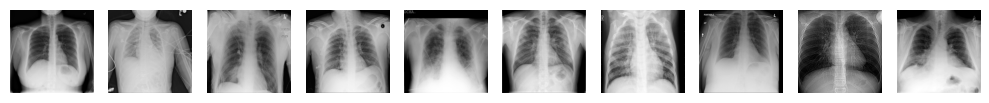

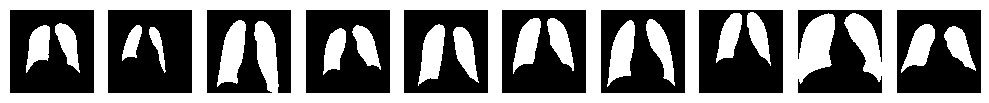

In [56]:
x = torch.stack([data_mask_train[i][0] for i in range(10)]).to(device)
y = torch.stack([data_mask_train[i][1] for i in range(10)]).to(device)
ts.show(x, nrows=1, figsize=(10, 2))
ts.show(y, nrows=1, figsize=(10, 2))

# Training Functions for Mask Detection

In [57]:
def run_mask_epoch(mdl, opt, loss, dataloader, is_train=True):
    mdl.train(is_train)
    total_loss = 0.0
    
    all_labels = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for x, y in tqdm(dataloader):
            x = x.to(device)
            y = y.to(device)
            
            y_pred = mdl(x)
            
            l = loss(y_pred, y)
            if (is_train):
                opt.zero_grad()
                l.backward()
                
                opt.step()
            
            
            total_loss += l.item() # loss
    
    return {"Loss": total_loss / len(dataloader.dataset), "F1": 0, "Recall": 0, "Precision": 0}

In [58]:
def run_mask_train_loop(mdl, opt, loss, train_loader, val_loader, num_epochs):
    train_hist = []
    val_hist = []
    metrics_hist = {"Loss": {"Train": [], "Test": []}, "F1":  {"Train": [], "Test": []}, "Recall":  {"Train": [], "Test": []}, "Precision":  {"Train": [], "Test": []}}
    
    for e in range(num_epochs):
        print("Trainin...")
        train_metrics = run_mask_epoch(mdl, opt, loss, train_loader)
        for key in metrics_hist.keys():
            metrics_hist[key]["Train"].append(train_metrics[key])
        
        print("Validating...")
        val_metrics = run_mask_epoch(mdl, opt, loss, val_loader, is_train=False)
        for key in metrics_hist.keys():
            metrics_hist[key]["Test"].append(val_metrics[key])
        
        clear_output()
        
        x = torch.stack([data_mask_train[i][0] for i in range(10)]).to(device)
        y = torch.stack([data_mask_train[i][1] for i in range(10)]).to(device)
        ts.show(x, nrows=1, figsize=(10, 2))
        ts.show(y, nrows=1, figsize=(10, 2))
        ts.show(mdl(x), nrows=1, figsize=(10, 2))
        
        plot_metrics(metrics_hist, num_epochs)

# UNet Architecture for Mask Detection

In [59]:
import torchvision.transforms.functional as TF


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernal_size, strides, padding):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_segmentations=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.bottleneck = DoubleConv(
            in_channels=features[-1],
            out_channels=features[-1]*2,
            kernal_size=3,
            strides=1,
            padding=1
        )
        self.output = nn.Conv2d(
            in_channels=features[0],
            out_channels=num_segmentations,
            kernel_size=1
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        in_channels_iter = in_channels
        for feature in features:
            self.downs.append(DoubleConv(
                    in_channels=in_channels_iter,
                    out_channels=feature,
                    kernal_size=3,
                    strides=1,
                    padding=1
                ))
            in_channels_iter = feature

        for feature in reversed(features):
            up = nn.Sequential(
                nn.ConvTranspose2d(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernel_size=2,
                    stride=2,
                    padding=0
                ),
                DoubleConv(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernal_size=3,
                    padding=1,
                    strides=1
                )
            )

            self.ups.append(up)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for i in range(len(self.ups)):
            x = self.ups[i][0](x) # Pass through ConvTranspose first

            skip_connection = skip_connections[i]

            # If the height and width of output tensor and skip connection
            # is not same then resize the tensor
            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            # Concat the output tensor with skip connection
            concat_x = torch.cat((skip_connection, x), dim=1)

            # Pass the concatinated tensor through DoubleCOnv
            x = self.ups[i][1](concat_x)

        return self.output(x)

unet_mask_model = UNet(in_channels=1).to(device)
summary(unet_mask_model, (1, 256, 256), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]             576
       BatchNorm2d-2         [-1, 64, 256, 256]             128
              ReLU-3         [-1, 64, 256, 256]               0
            Conv2d-4         [-1, 64, 256, 256]          36,864
       BatchNorm2d-5         [-1, 64, 256, 256]             128
              ReLU-6         [-1, 64, 256, 256]               0
        DoubleConv-7         [-1, 64, 256, 256]               0
         MaxPool2d-8         [-1, 64, 128, 128]               0
            Conv2d-9        [-1, 128, 128, 128]          73,728
      BatchNorm2d-10        [-1, 128, 128, 128]             256
             ReLU-11        [-1, 128, 128, 128]               0
           Conv2d-12        [-1, 128, 128, 128]         147,456
      BatchNorm2d-13        [-1, 128, 128, 128]             256
             ReLU-14        [-1, 128, 1

In [60]:
num_samples = len(data_mask_train)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_mask_train, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


In [61]:
batch_size = 16
num_epochs = 10

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(unet_mask_model.parameters())
criterion = nn.MSELoss()

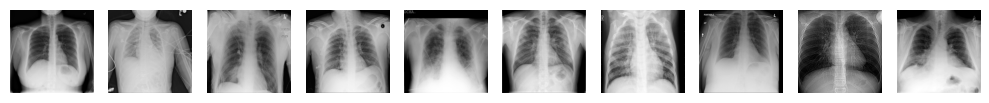

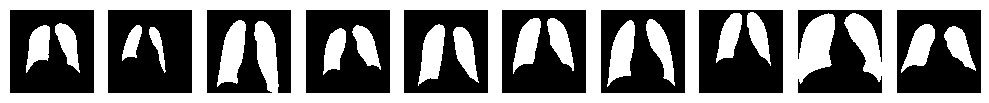

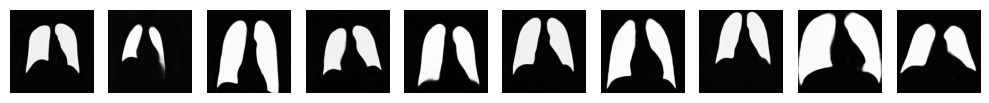

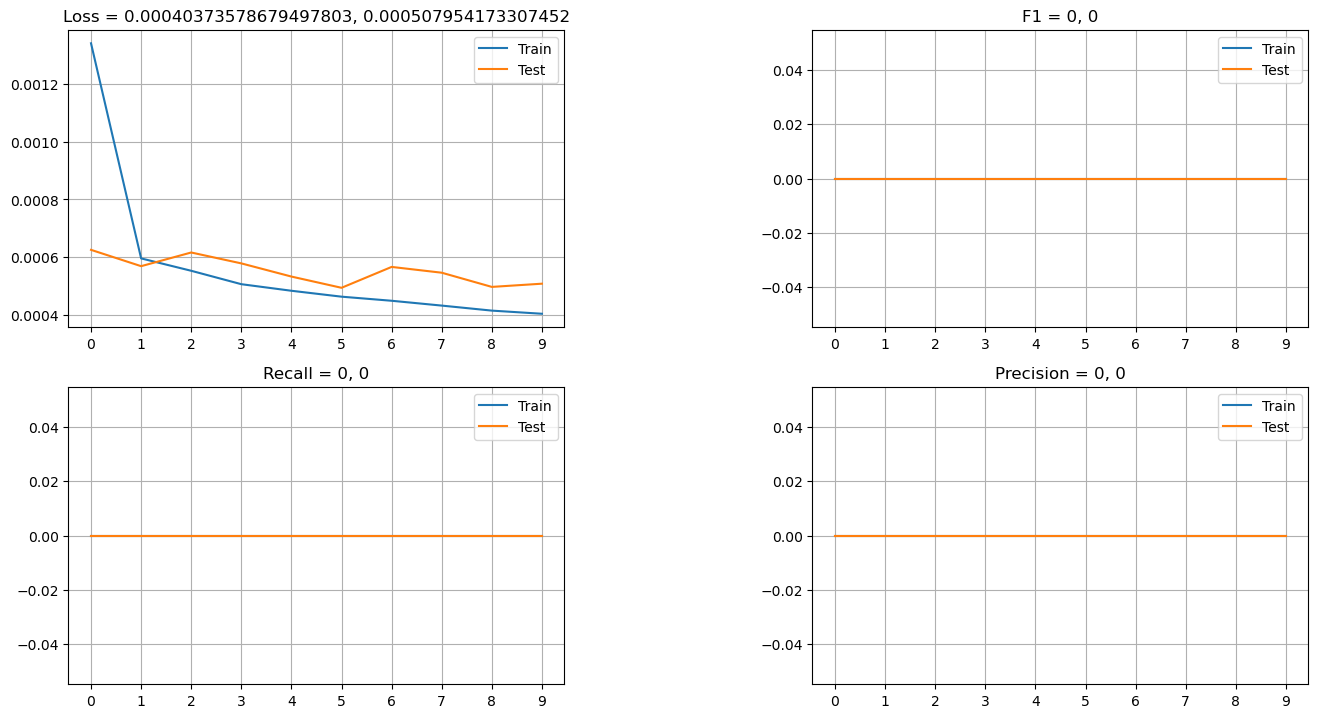

In [62]:
run_mask_train_loop(unet_mask_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

# Generating and Saving Masks for Train/Test Sets

In [73]:
unet_mask_model.eval()

for i in range(len(data_mask_train)):
    if i%1000 == 0:
        print(i)
    out_tensor = unet_mask_model(data_mask_train[i][0].unsqueeze(1).to(device))
    out_tensor = out_tensor > threshold
    
    numpy_image = out_tensor.cpu().numpy()
    
    rescaled_image = (numpy_image * 255).astype(np.uint8)
    image = Image.fromarray(rescaled_image.squeeze(), mode='L')
    image.save(f'data/train_lung_masks_generated/img_{i}.png')

0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000
14000
15000
16000
17000
18000
19000
20000
21000
22000
23000
24000
25000
26000


In [75]:
!tar -czf train_masks.tar.gz data/train_lung_masks_generated

In [77]:
data_test = MaskDataset(y_dir='data/train_lung_masks', x_dir='data/test_images', transform=transform)

for i in range(len(data_test)):
    out_tensor = unet_mask_model(data_test[i][0].unsqueeze(1).to(device))
    out_tensor = out_tensor > threshold
    
    numpy_image = out_tensor.cpu().numpy()
    
    rescaled_image = (numpy_image * 255).astype(np.uint8)
    image = Image.fromarray(rescaled_image.squeeze(), mode='L')
    image.save(f'data/test_lung_masks_generated/img_{i}.png')

In [78]:
!tar -czf test_masks.tar.gz data/test_lung_masks_generated

# Classification Models Using Mask Enhancement

# Simple Dataset with Masks

In [79]:
from torchvision.transforms import ToPILImage

class LungsWithMasksDataset(Dataset):
    def __init__(self, csv_file, root_dir, mask_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.mask_dir = mask_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
        
        msk_path = os.path.join(self.mask_dir, str('img_' + str(idx) + '.png'))
        mask = Image.open(msk_path).convert('RGB')
        
        to_tensor = transforms.ToTensor()
        
        image = to_tensor(image)
        mask = to_tensor(mask)
        
        # image = image * mask + (-1) * (mask-1) * torch.rand(mask.shape)
        image = image * mask

        label = self.df.iloc[idx, 1]

        if self.transform:
            to_pil = ToPILImage()
            image = to_pil(image)
            
            image = self.transform(image)

        return image, label


raw_transform = transforms.Compose([ # to_tensor is applied in the dataset
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_train_raw = LungsWithMasksDataset(csv_file='data/train_answers.csv', root_dir='data/train_images', mask_dir='data/train_lung_masks', transform=raw_transform)

In [80]:
data_train_raw[0][0].shape

torch.Size([1, 256, 256])

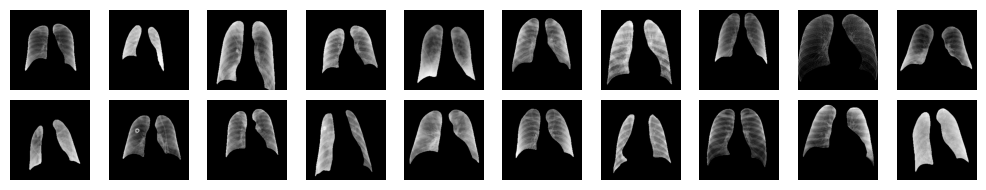

In [81]:
x = torch.stack([data_train_raw[i][0] * 0.5 + 0.5 for i in range(20)]).to(device)
ts.show(x, nrows=2, figsize=(10, 2))

# SimpleConvNet with Mask Enhancement

In [82]:
simple_conv_model_wm = SimpleConvNet().to(device)
summary(simple_conv_model_wm, (1, 256, 256), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 252, 252]             416
              ReLU-2         [-1, 16, 252, 252]               0
            Conv2d-3         [-1, 16, 248, 248]           6,416
              ReLU-4         [-1, 16, 248, 248]               0
         MaxPool2d-5           [-1, 16, 62, 62]               0
            Conv2d-6           [-1, 32, 58, 58]          12,832
              ReLU-7           [-1, 32, 58, 58]               0
            Conv2d-8           [-1, 32, 54, 54]          25,632
              ReLU-9           [-1, 32, 54, 54]               0
        MaxPool2d-10           [-1, 32, 27, 27]               0
           Conv2d-11           [-1, 64, 24, 24]          32,832
             ReLU-12           [-1, 64, 24, 24]               0
           Conv2d-13           [-1, 64, 20, 20]         102,464
             ReLU-14           [-1, 64,

In [83]:
num_samples = len(data_train_raw)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train_raw, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


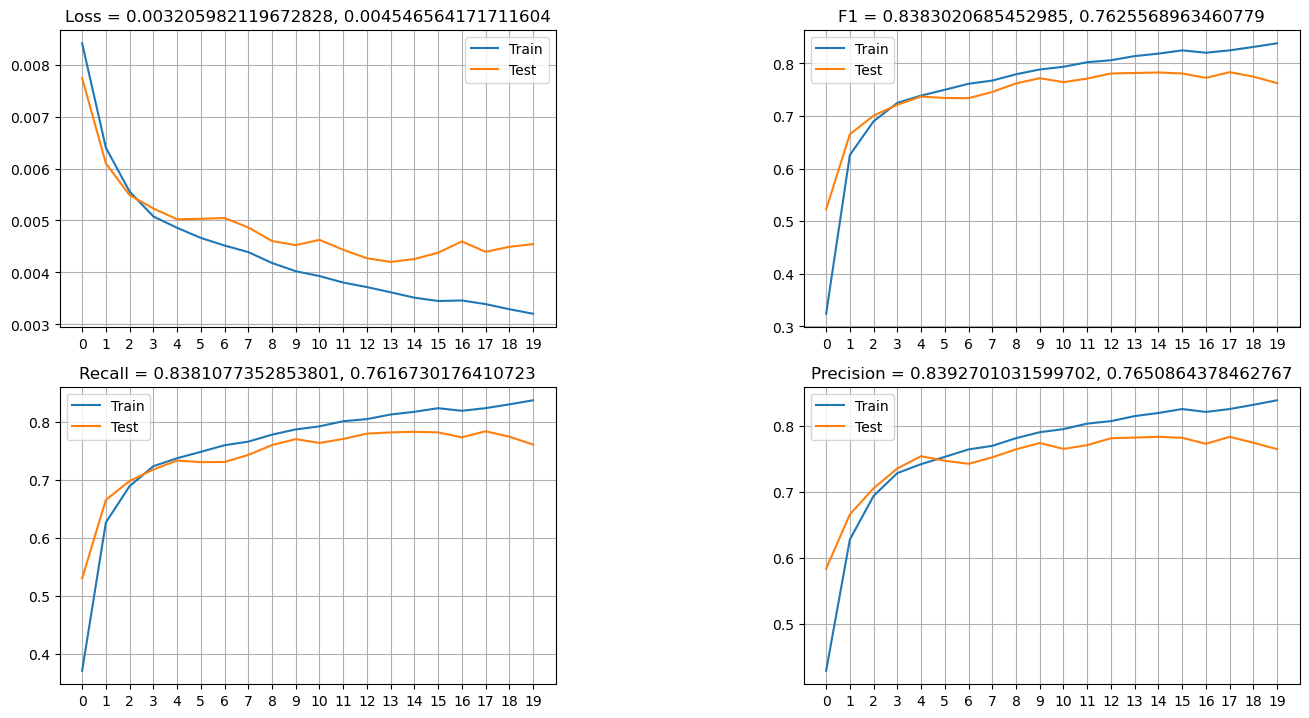

In [84]:
batch_size = 128
num_epochs = 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(simple_conv_model_wm.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(simple_conv_model_wm, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

# Modified AlexNet with Mask Enhancement

In [85]:
alex_net_model_wm = AlexNet().to(device)
summary(alex_net_model_wm, (1, 224, 224), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 55, 55]           7,808
              ReLU-2           [-1, 64, 55, 55]               0
         MaxPool2d-3           [-1, 64, 27, 27]               0
            Conv2d-4          [-1, 192, 27, 27]         307,392
              ReLU-5          [-1, 192, 27, 27]               0
         MaxPool2d-6          [-1, 192, 13, 13]               0
            Conv2d-7          [-1, 384, 13, 13]         663,936
              ReLU-8          [-1, 384, 13, 13]               0
            Conv2d-9          [-1, 256, 13, 13]         884,992
             ReLU-10          [-1, 256, 13, 13]               0
           Conv2d-11          [-1, 256, 13, 13]         590,080
             ReLU-12          [-1, 256, 13, 13]               0
        MaxPool2d-13            [-1, 256, 6, 6]               0
AdaptiveAvgPool2d-14            [-1, 25

In [86]:
data_train_alexnet = LungsWithMasksDataset(csv_file='data/train_answers.csv', root_dir='data/train_images', mask_dir='data/train_lung_masks', transform=alex_transform)

num_samples = len(data_train_alexnet)
num_test = int(0.1 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train_alexnet, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 24300 
 Test len: 2700


In [87]:
data_train_alexnet[0][0][0]

tensor([[-1., -1., -1.,  ..., -1., -1., -1.],
        [-1., -1., -1.,  ..., -1., -1., -1.],
        [-1., -1., -1.,  ..., -1., -1., -1.],
        ...,
        [-1., -1., -1.,  ..., -1., -1., -1.],
        [-1., -1., -1.,  ..., -1., -1., -1.],
        [-1., -1., -1.,  ..., -1., -1., -1.]])

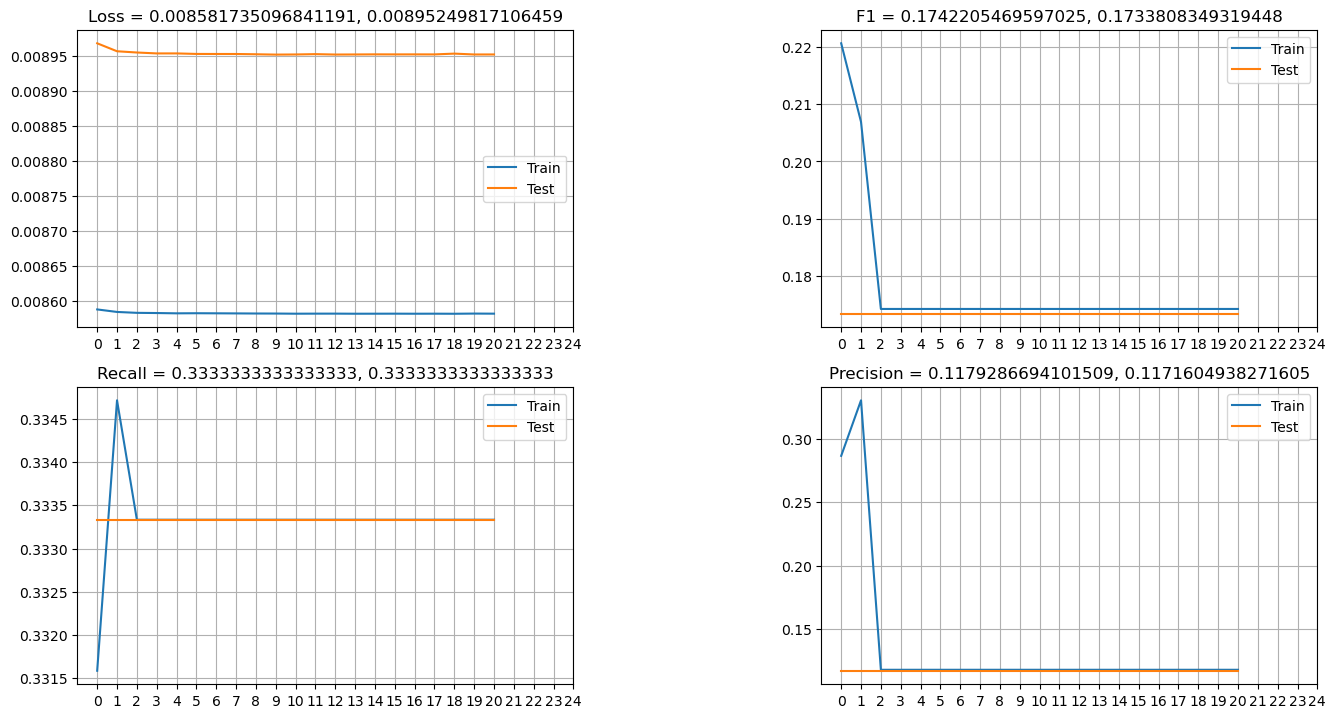

Trainin...


 13%|██████████▏                                                                      | 24/190 [00:12<01:25,  1.94it/s]


KeyboardInterrupt: 

In [88]:
batch_size = 128
num_epochs = 25

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model_wm.parameters())
criterion = torch.nn.CrossEntropyLoss()

 
run_train_loop(alex_net_model_wm, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

**Observation**: Gradient behavior becomes unstable with masks (vanishing or exploding gradients). Surprisingly, simpler models show worse performance with masks compared to without masks. Further investigation needed.

# Conclusion:

This notebook demonstrates a comprehensive approach to medical image classification, ranging from simple convolutional networks to hybrid models combining autoencoders with AlexNet. The implementation includes advanced techniques such as automatic mask generation and mask-guided training. While mask-based approaches show promise for medical imaging tasks, the current implementation reveals challenges in gradient stability that warrant further investigation and optimization.